# 02 – Baselines

Before training a neural network we need something to compare it with. This notebook builds two baselines:

| Model | Idea | Why include it |
|---|---|---|
| **Always FAIL** | Rejects every tray | Shows what a useless model scores – any real model must beat it |
| **Colour histogram + logistic regression** | Describes each photo by its colours, then fits a linear classifier | A simple, fast, explainable model using a technique from the unit |

**How models are compared** (see `src/rasher_inspection/evaluate.py`): about 80% of photos are FAIL, so plain accuracy is misleading. We report

* **defects caught** – share of FAIL photos predicted FAIL (a miss sends a faulty tray to a customer),
* **good trays passed** – share of PASS photos predicted PASS (a false reject wastes a good tray),
* **balanced accuracy** – the average of the two (always FAIL scores exactly 50%),

each with a 95% confidence interval, because the test set is small (80 photos, 12 PASS).

In [2]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path("..") / "src"))
from rasher_inspection.data import FAIL, PASS, SPLITS, load_dataset
from rasher_inspection.evaluate import format_summary, summarise
from rasher_inspection.features import colour_histogram

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

# Fixed colour per model, reused in later notebooks.
MODEL_COLOURS = {"Always FAIL": "#c3c2b7", "Colour histogram": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

data = load_dataset(DATA_DIR)
y = {s: np.array([r.label for r in data[s]]) for s in SPLITS}
print({s: len(data[s]) for s in SPLITS})

{'train': 3349, 'valid': 120, 'test': 80}


## 1. Baseline 0 – Always FAIL

In [3]:
results = {}  # model name -> {"valid": summary, "test": summary}

results["Always FAIL"] = {s: summarise(y[s], np.full(len(y[s]), FAIL)) for s in ("valid", "test")}
print(format_summary("Always FAIL – test set", results["Always FAIL"]["test"]))

Always FAIL – test set   (caught 68, missed 0, passed 0, rejected 12)
  Balanced accuracy   50.0%   (95% CI 50.0% – 50.0%)
  Defects caught     100.0%   (95% CI 94.7% – 100.0%)
  Good trays passed    0.0%   (95% CI  0.0% – 24.3%)
  Accuracy            85.0%   (95% CI 75.6% – 91.2%)


Always FAIL reaches 85% accuracy while being useless: it never passes a good tray. This is why balanced accuracy is the headline metric.

## 2. Baseline 1 – Colour histogram + logistic regression

**Features.** Each photo is converted to HSV (hue = colour, saturation = colour strength, value = brightness) and each channel is summarised by a 16-bin histogram: the fraction of pixels in each range. That gives 48 numbers per photo (`features.colour_histogram`). They describe *which colours appear and how much of each*, but not *where*.

**Classifier.** Logistic regression fits a weighted sum of the 48 features and passes it through a sigmoid to give P(FAIL). Two settings matter:

* `StandardScaler` puts all features on the same scale first, so no feature dominates just because of its units;
* `class_weight="balanced"` makes a mistake on a (rare) PASS photo count as much as all the FAIL mistakes together – otherwise the model would drift towards "always FAIL".

**Feature extraction:**

In [4]:
features = {}
start = time.perf_counter()
for s in SPLITS:
    features[s] = np.stack([colour_histogram(r.path) for r in data[s]])
n_photos = sum(len(data[s]) for s in SPLITS)
feature_ms = 1000 * (time.perf_counter() - start) / n_photos
print(f"Feature shape (train): {features['train'].shape}; {feature_ms:.1f} ms per photo")

Feature shape (train): (3349, 48); 3.4 ms per photo


**Choosing the regularisation strength `C`.** Smaller `C` means a simpler model (weights pushed towards zero), larger `C` lets the model fit the training data more closely.

The validation set has only 14 PASS photos, which is too few to choose a setting reliably. Instead we use **5-fold cross-validation on the training set**. The 3 exposure copies of a photo must stay in the same fold – otherwise the model would be tested on a copy of a photo it trained on – so the folds are grouped by original photo (`GroupKFold`).

In [5]:
groups = [r.source for r in data["train"]]  # copies of one photo share a group
cv = GroupKFold(n_splits=5)

def colour_model(C):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

cv_scores = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    scores = cross_val_score(colour_model(C), features["train"], y["train"],
                             groups=groups, cv=cv, scoring="balanced_accuracy")
    cv_scores[C] = scores
    print(f"C = {C:<6} balanced accuracy {scores.mean():.1%} ± {scores.std():.1%}  (5 folds)")

best_C = max(cv_scores, key=lambda C: cv_scores[C].mean())
print(f"\nChosen C = {best_C}")

C = 0.001  balanced accuracy 58.6% ± 4.6%  (5 folds)
C = 0.01   balanced accuracy 60.1% ± 3.9%  (5 folds)
C = 0.1    balanced accuracy 60.1% ± 4.2%  (5 folds)
C = 1      balanced accuracy 59.5% ± 4.2%  (5 folds)
C = 10     balanced accuracy 59.7% ± 4.0%  (5 folds)

Chosen C = 0.01


All values of `C` score within about 2 percentage points of each other – smaller than the fold-to-fold spread – so the choice hardly matters. The colour baseline is clearly better than guessing (50%) but far from perfect.

**Train the final model on the whole training set and evaluate:**

In [6]:
model = colour_model(best_C)
start = time.perf_counter()
model.fit(features["train"], y["train"])
train_seconds = time.perf_counter() - start

start = time.perf_counter()
predictions = {s: model.predict(features[s]) for s in ("valid", "test")}
predict_ms = 1000 * (time.perf_counter() - start) / (len(y["valid"]) + len(y["test"]))

results["Colour histogram"] = {s: summarise(y[s], predictions[s]) for s in ("valid", "test")}
print(format_summary("Colour histogram – validation set", results["Colour histogram"]["valid"]))
print()
print(format_summary("Colour histogram – test set", results["Colour histogram"]["test"]))
print(f"\nTraining time: {train_seconds:.2f} s.  Time per photo: {feature_ms:.1f} ms features "
      f"+ {predict_ms:.3f} ms prediction")

Colour histogram – validation set   (caught 97, missed 9, passed 7, rejected 7)
  Balanced accuracy   70.8%   (95% CI 56.5% – 84.3%)
  Defects caught      91.5%   (95% CI 84.6% – 95.5%)
  Good trays passed   50.0%   (95% CI 26.8% – 73.2%)
  Accuracy            86.7%   (95% CI 79.4% – 91.6%)

Colour histogram – test set   (caught 55, missed 13, passed 7, rejected 5)
  Balanced accuracy   69.6%   (95% CI 53.7% – 83.9%)
  Defects caught      80.9%   (95% CI 70.0% – 88.5%)
  Good trays passed   58.3%   (95% CI 32.0% – 80.7%)
  Accuracy            77.5%   (95% CI 67.2% – 85.3%)

Training time: 0.01 s.  Time per photo: 3.4 ms features + 0.003 ms prediction


## 3. Comparison on the test set

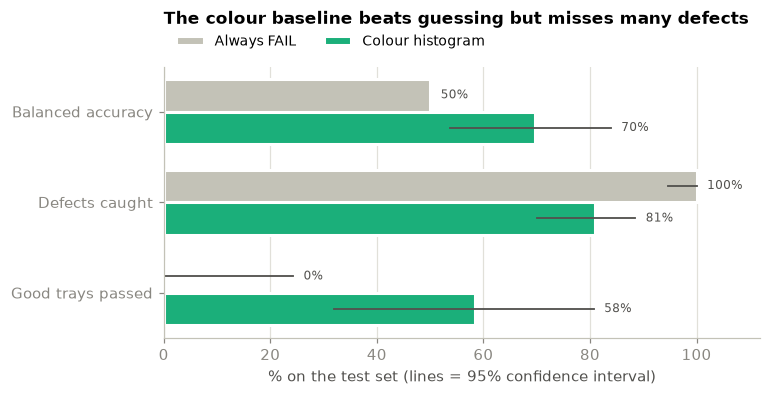

In [7]:
metrics = [("balanced_accuracy", "Balanced accuracy"), ("defects_caught", "Defects caught"),
           ("good_passed", "Good trays passed")]
names = list(results)
height = 0.36

fig, ax = plt.subplots(figsize=(7, 3.2))
for k, name in enumerate(names):
    for m, (key, label) in enumerate(metrics):
        s = results[name]["test"][key]
        lo, hi = s["ci"]
        yy = m + (k - 0.5) * height
        ax.barh(yy, 100 * s["value"], height=height, color=MODEL_COLOURS[name],
                edgecolor="white", linewidth=2, label=name if m == 0 else None)
        ax.plot([100 * lo, 100 * hi], [yy, yy], color="#52514e", linewidth=1.2)
        ax.text(100 * max(s["value"], hi) + 2, yy, f"{s['value']:.0%}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(metrics)), [label for _, label in metrics])
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("% on the test set (lines = 95% confidence interval)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=len(names), fontsize=9)
ax.set_title("The colour baseline beats guessing but misses many defects", pad=28)
fig.savefig(RESULTS_DIR / "02_baselines_test.png")
plt.show()

In [8]:
# Save the numbers so the final comparison notebook can reuse them.
import json

results["Colour histogram"]["ms_per_photo"] = feature_ms + predict_ms
results["Colour histogram"]["chosen_C"] = best_C
with open(RESULTS_DIR / "02_baselines.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved", RESULTS_DIR / "02_baselines.json")

Saved ../results/02_baselines.json


## What this tells us

* **Always FAIL** has the best *accuracy* of the two on the test set but a balanced accuracy of exactly 50% – it is useless for inspection. Accuracy should not be used to compare models here.
* **The colour baseline** does better than guessing, but in cross-validation it only reaches about 60% balanced accuracy. That is expected: colour tells you *how much* meat and plastic is visible, but defects such as an unsealed lid or a twisted rasher are about **shape and position**, which a histogram throws away.
* Its test result looks better than its cross-validation result, but the 95% interval is very wide (roughly 54–84%), so the test set alone cannot tell us its true performance precisely.
* It is extremely cheap (about 8 ms per photo, mostly for loading the image) and easy to explain.

**Next:** a CNN keeps spatial information, so it should be able to see shapes and edges. The question for notebook 03 is whether that extra accuracy justifies the extra computation.